# 04 · Campaign & Pricing Analytics
ตอบคำถามวิเคราะห์ข้อ 3: **การได้รับแคมเปญสัมพันธ์กับการซื้อและการใช้คูปองอย่างไร?**
และดูความอ่อนไหวต่อโปรโมชันของแต่ละกลุ่ม

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.viz import setup, save, seg_palette, PRIMARY, ACCENT, MUTED
setup()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 160)

In [2]:
from src.data import load, load_transactions_clean
tx = load_transactions_clean()
seg = pd.read_parquet(config.PROCESSED_DIR / "segments.parquet")
ORDER = config.SEGMENT_ORDER
tx["segment"] = tx.household_key.map(seg.segment)

ct, cd = load("campaign_table"), load("campaign_desc")
coupon, redempt = load("coupon"), load("coupon_redempt")
assert len(redempt) == 2318

## 1. แคมเปญเข้าถึงใคร?

In [3]:
camp = cd.assign(days=cd.END_DAY - cd.START_DAY + 1).sort_values("START_DAY")
reach = ct.groupby("DESCRIPTION").agg(campaigns=("CAMPAIGN", "nunique"), sends=("household_key", "size"),
                                      households=("household_key", "nunique"))
reach["unique coupons offered"] = (coupon.drop_duplicates().merge(cd, on="CAMPAIGN")
                                   .groupby("DESCRIPTION").COUPON_UPC.nunique())
reach["avg days"] = camp.groupby("DESCRIPTION").days.mean()
display(reach)

reached = ct.household_key.unique()
seg_reach = pd.DataFrame({
    "households": seg.segment.value_counts(),
    "reached by >=1 campaign": seg.loc[seg.index.isin(reached), "segment"].value_counts(),
    "campaign sends": ct.household_key.map(seg.segment).value_counts(),
}).reindex(ORDER)
seg_reach["% reached"] = seg_reach.iloc[:, 1] / seg_reach.households * 100
seg_reach["% of all sends"] = seg_reach["campaign sends"] / seg_reach["campaign sends"].sum() * 100
print(f"households reached: {len(reached):,} of 2,500 ({len(reached) / 2500:.0%})")
seg_reach

,campaigns,sends,households,unique coupons offered,avg days
DESCRIPTION,,,,,
TypeA,5,3979,1513,866,48.20
TypeB,19,2655,1023,256,38.63
TypeC,6,574,397,74,75.50


households reached: 1,584 of 2,500 (63%)


,households,reached by >=1 campaign,campaign sends,% reached,% of all sends
Champions,916,893,5364,97.49,74.42
Loyal,647,325,734,50.23,10.18
At Risk,575,354,1097,61.57,15.22
Occasional,362,12,13,3.31,0.18


**ผล:** แคมเปญเข้าถึง 1,584 ครัวเรือน (63%) โดย **~74% ของการส่งไปที่ Champions** — ร้านเลือกส่งให้คนที่ซื้อเยอะอยู่แล้ว
(เป็นเหตุผลที่เทียบ "ได้รับ vs ไม่ได้รับ" ตรง ๆ ไม่ได้ ดูหัวข้อ 3) · At Risk ได้รับ ~15% และ Occasional แทบไม่ได้รับเลย
(กลุ่มนิยามจากยอดตลอด 2 ปี จึงสัมพันธ์กับการถูกเลือกส่งอยู่แล้ว)

## 2. การใช้คูปอง (redemption)

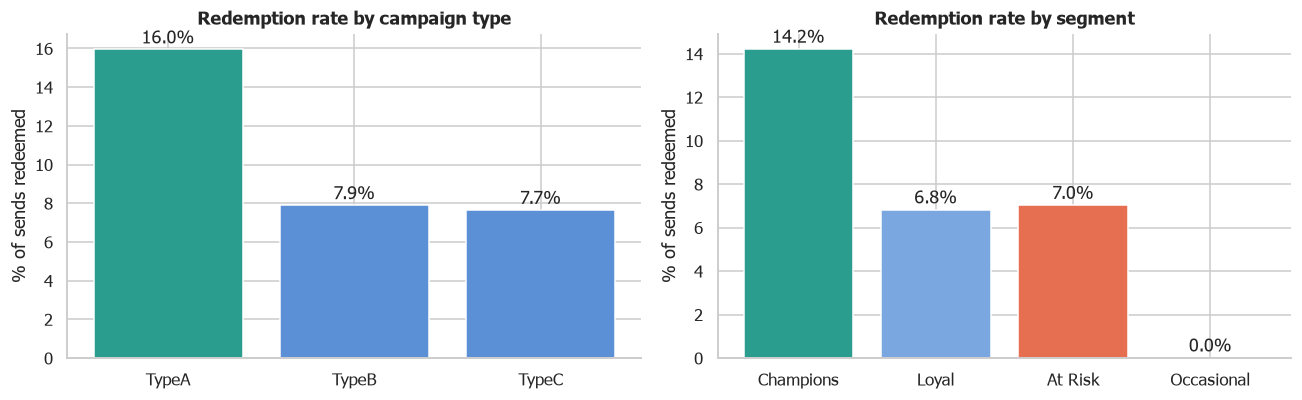

households that ever redeemed: 434 of 1584 reached (27%) -> 73% never used a campaign coupon


DESCRIPTION,TypeA,TypeB,TypeC
segment,,,
Champions,19.800000,8.700000,8.100000
Loyal,8.200000,2.800000,4.800000
At Risk,7.900000,5.200000,5.100000
Occasional,0.000000,0.000000,nan


In [4]:
red = redempt[["household_key", "CAMPAIGN"]].drop_duplicates().assign(redeemed=1)
sends = ct.merge(red, on=["household_key", "CAMPAIGN"], how="left").fillna({"redeemed": 0})
sends["segment"] = sends.household_key.map(seg.segment)

by_type = sends.groupby("DESCRIPTION").redeemed.agg(sends="size", redemption_rate="mean")
by_seg = sends.groupby("segment").redeemed.agg(sends="size", redemption_rate="mean").reindex(ORDER)
by_type_seg = sends.pivot_table(index="segment", columns="DESCRIPTION", values="redeemed", aggfunc="mean").reindex(ORDER) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(by_type.index, by_type.redemption_rate * 100, color=[ACCENT, PRIMARY, PRIMARY])
axes[0].set(title="Redemption rate by campaign type", ylabel="% of sends redeemed")
axes[1].bar(by_seg.index, by_seg.redemption_rate * 100, color=seg_palette())
axes[1].set(title="Redemption rate by segment", ylabel="% of sends redeemed")
for ax, vals in zip(axes, [by_type.redemption_rate, by_seg.redemption_rate]):
    for i, v in enumerate(vals):
        ax.text(i, v * 100 + .3, f"{v:.1%}", ha="center")
plt.tight_layout()
save(fig, "04_redemption")
plt.show()

ever = redempt.household_key.nunique()
print(f"households that ever redeemed: {ever} of {len(reached)} reached ({ever / len(reached):.0%}) "
      f"-> {1 - ever / len(reached):.0%} never used a campaign coupon")
display(by_type_seg.round(1).style.set_caption("Redemption rate % — segment x campaign type"))

**ผล:**
- **Type A ได้อัตราใช้คูปองสูงสุด (~16%)** สูงกว่า Type B/C (~8%) ราว 2 เท่า
- ครัวเรือนที่ได้รับแคมเปญ **73% ไม่เคยใช้คูปองเลย**
- Champions ใช้คูปองบ่อยกว่ากลุ่มอื่น ~2 เท่า (~14% vs ~7%) — สอดคล้องกับที่ร้านส่งให้คนที่ซื้อเยอะอยู่แล้ว
  แต่การใช้คูปอง ≠ ยอดซื้อที่เพิ่มขึ้น (ดูหัวข้อ 3)

## 3. แคมเปญเพิ่มยอดซื้อจริงไหม? (Campaign lift)
**ปัญหา:** ร้านเลือกส่งแคมเปญให้ลูกค้าที่ซื้อเยอะอยู่แล้ว เทียบ "ได้รับ vs ไม่ได้รับ" ตรง ๆ จะเกินจริง (selection bias)

**วิธี (Difference-in-Differences):** ต่อแคมเปญ คำนวณ lift = ยอดซื้อต่อสัปดาห์ *ช่วงแคมเปญ − ช่วงก่อนแคมเปญ* (ยาวเท่ากัน)
แล้วเทียบคนที่ได้รับกับไม่ได้รับ ภายในกลุ่มลูกค้าที่ **ยอดซื้อก่อนหน้าใกล้กัน (quintile)**

**ต้องเลือกว่าจะจับกลุ่มด้วยยอดซื้อช่วงไหน** จึงเปรียบ 2 วิธี และตรวจด้วย **placebo test**
(เลื่อนทุกแคมเปญไปก่อนหน้า 1 ช่วงที่ยังไม่มีแคมเปญ — วิธีที่ถูกต้องต้องให้ผลใกล้ 0):
- `pre` — จับกลุ่มด้วยยอดช่วงก่อนแคมเปญ (ช่วงเดียวกับที่ใช้ลบใน lift)
- `prepre` — จับกลุ่มด้วยยอดช่วงก่อนหน้านั้นอีกช่วง

ไม่ใช้ segment เป็นตัวจับกลุ่ม เพราะ segment ถูกนิยามจากทั้ง 2 ปี (รวมพฤติกรรม *หลัง* แคมเปญ)

In [5]:
from src.campaign import build_cells, summarize

runs = {}
for strat in ["pre", "prepre"]:
    for shift, label in [(0, "actual"), (1, "placebo")]:
        runs[(strat, label)] = build_cells(tx, seg.first_day, ct, cd, shift=shift, strat=strat)

rows = []
for (strat, label), (cells, n_hh) in runs.items():
    r = summarize(cells, n_hh, None, n_boot=200).iloc[0].to_dict()
    rows.append({"stratify on": strat, "window": label, "campaigns": cells.campaign.nunique(), **r})
overall = pd.DataFrame(rows)
display(overall)

cells_a, n_hh = runs[("prepre", "actual")]
pre_mean = cells_a.loc[cells_a.targeted, "pre"].mean()
print(f"avg weekly spend of targeted households before campaigns: ${pre_mean:,.1f}")

,stratify on,window,campaigns,lift_per_week,ci_low,ci_high
0,pre,actual,30,6.18,5.00,7.39
1,pre,placebo,30,6.51,5.23,7.83
2,prepre,actual,30,0.76,-0.36,1.94
3,prepre,placebo,30,0.18,-1.26,1.54


avg weekly spend of targeted households before campaigns: $67.0


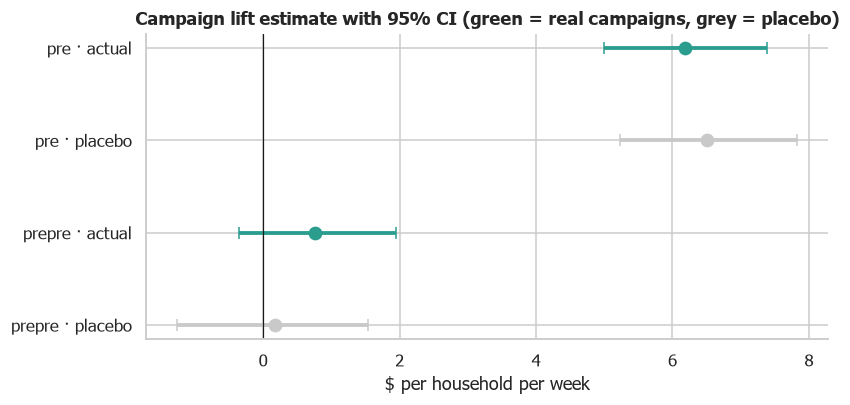

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
labels, ypos = [], 0
for strat in ["pre", "prepre"]:
    for label, color in [("actual", ACCENT), ("placebo", MUTED)]:
        r = overall[(overall["stratify on"] == strat) & (overall.window == label)].iloc[0]
        ax.errorbar(r.lift_per_week, ypos, xerr=[[r.lift_per_week - r.ci_low], [r.ci_high - r.lift_per_week]],
                    fmt="o", color=color, capsize=4, lw=2.5, ms=8)
        labels.append(f"{strat} · {label}"); ypos += 1
ax.axvline(0, color="k", lw=.8)
ax.set_yticks(range(len(labels)), labels); ax.invert_yaxis()
ax.set(title="Campaign lift estimate with 95% CI (green = real campaigns, grey = placebo)",
       xlabel="$ per household per week")
save(fig, "04_campaign_lift")
plt.show()

In [7]:
cells_p, _ = runs[("prepre", "placebo")]
by_type = (summarize(cells_a, n_hh, "type").add_prefix("actual_")
           .join(summarize(cells_p, n_hh, "type").add_prefix("placebo_")))
by_type["n_targeted_households"] = cells_a[cells_a.targeted].groupby("type").hh_idx.nunique()
display(by_type)

overall.to_parquet(config.PROCESSED_DIR / "campaign_lift_overall.parquet")
by_type.to_parquet(config.PROCESSED_DIR / "campaign_lift_by_type.parquet")

,actual_lift_per_week,actual_ci_low,actual_ci_high,placebo_lift_per_week,placebo_ci_low,placebo_ci_high,n_targeted_households
type,,,,,,,
TypeA,0.93,-0.71,2.69,0.26,-1.75,2.47,1513
TypeB,0.04,-1.25,1.58,0.56,-0.81,1.84,1023
TypeC,2.87,0.19,5.85,-2.16,-5.24,0.73,397


**ผล:**
- วิธี `pre` ให้ lift ราว **+$6/สัปดาห์** แต่ช่วง placebo (ไม่มีแคมเปญ) ก็ให้ค่า **เกือบเท่ากัน** → เป็นความคลาดเคลื่อนของวิธี
  (regression to the mean) ไม่ใช่ผลของแคมเปญ ต้องไม่ใช้
- วิธี `prepre` **ผ่าน placebo** (ช่วงความเชื่อมั่นของ placebo ครอบคลุม 0): แคมเปญโดยรวมเพิ่มยอดซื้อ
  **+$0.76/ครัวเรือน/สัปดาห์ (95% CI −0.4 ถึง +1.9)** — **ไม่ต่างจากศูนย์อย่างมีนัยสำคัญ**
- ค่าบวกสูงสุดที่ข้อมูลยังไม่ตัดทิ้งคือ ~+$1.9 ต่อสัปดาห์ (~3% ของยอดซื้อก่อนแคมเปญ ~$67) ผลที่เล็กกว่านี้ **ข้อมูลชุดนี้วัดไม่ได้**
- **แยกตามประเภทไม่ได้ข้อสรุป:** Type C ดูเป็นบวก (+$2.9) แต่ placebo ของ Type C ติดลบ (−$2.2) และมีผู้ได้รับเพียง ~400 ครัวเรือน
  ส่วน Type A/B ช่วงความเชื่อมั่นครอบคลุม 0 → **บอกไม่ได้ว่าประเภทไหนดีกว่า**

**ข้อสรุปที่ข้อมูลรองรับ:** ยังไม่มีหลักฐานว่าแคมเปญเพิ่มยอดซื้อ (และก็ยังตัดความเป็นไปได้ที่เพิ่มเล็กน้อยไม่ได้)
อัตราการใช้คูปองไม่ใช่ตัวชี้วัดผล เพราะผู้ใช้คูปองคือคนที่ซื้ออยู่แล้ว → ต้องวัดด้วย **holdout group แบบสุ่ม**

ข้อจำกัด: ทั้ง 30 แคมเปญทับซ้อนช่วงเวลากัน กลุ่มเทียบจึงอาจได้รับแคมเปญอื่นอยู่ · ยอดซื้อรายสัปดาห์ผันผวนสูง · ไม่มีข้อมูลต้นทุนคูปองจึงคำนวณ ROI ไม่ได้

## 4. Pricing & Promotion sensitivity
ไม่นับน้ำมัน (`KIOSK-GAS`) และ `MISC. TRANS.` — น้ำมันถูกบันทึกว่าลดราคาถึง ~95% แต่ส่วนลดรวมเพียง ~$17K จะทำให้สัดส่วนโปรโมชันดูสูงเกินจริง

,promo sales %,discount depth %,private label %,discount $ per hh
segment,,,,
Champions,47.00,15.04,22.41,"1,010.67"
Loyal,47.39,16.05,22.63,293.82
At Risk,47.97,16.35,23.11,392.11
Occasional,46.72,16.45,23.24,68.39


overall (excl. fuel): 47.2% of sales sold on retail discount · retail discount $1,366,103 vs coupon discount $32,235 (42x)


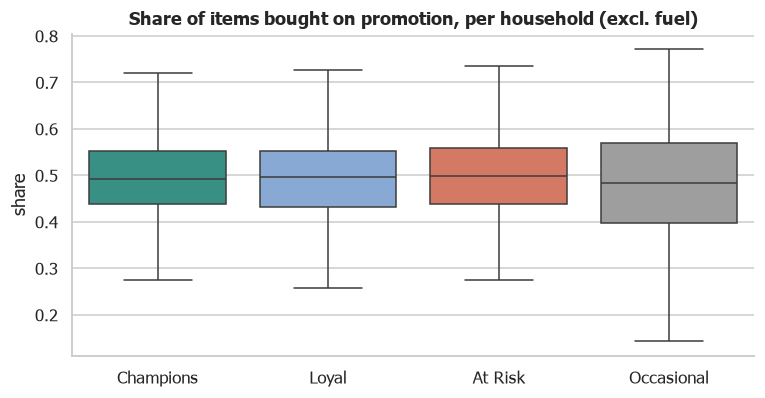

In [8]:
merch = tx[~tx.is_non_merch]
price = merch.groupby("segment").agg(sales=("SALES_VALUE", "sum"), retail_disc=("retail_disc", "sum"))
price["promo sales %"] = merch[merch.on_promo].groupby("segment").SALES_VALUE.sum() / price.sales * 100
price["discount depth %"] = price.retail_disc / (price.sales + price.retail_disc) * 100
price["private label %"] = merch[merch.BRAND == "Private"].groupby("segment").SALES_VALUE.sum() / price.sales * 100
price["discount $ per hh"] = price.retail_disc / seg.segment.value_counts()
price = price.reindex(ORDER)
display(price[["promo sales %", "discount depth %", "private label %", "discount $ per hh"]])

overall_promo = merch[merch.on_promo].SALES_VALUE.sum() / merch.SALES_VALUE.sum()
print(f"overall (excl. fuel): {overall_promo:.1%} of sales sold on retail discount · "
      f"retail discount ${merch.retail_disc.sum():,.0f} vs coupon discount ${tx.coupon_disc.sum():,.0f} "
      f"({merch.retail_disc.sum() / tx.coupon_disc.sum():.0f}x)")

hh_promo = merch.groupby("household_key").on_promo.mean().rename("promo_share").to_frame().join(seg.segment)
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.boxplot(data=hh_promo, x="segment", y="promo_share", order=ORDER, palette=seg_palette(), showfliers=False, ax=ax)
ax.set(title="Share of items bought on promotion, per household (excl. fuel)", xlabel="", ylabel="share")
save(fig, "04_promo_sensitivity")
plt.show()

In [9]:
dept_promo = (merch[merch.on_promo].groupby("DEPARTMENT").SALES_VALUE.sum()
              / merch.groupby("DEPARTMENT").SALES_VALUE.sum() * 100)
top = merch.groupby("DEPARTMENT").SALES_VALUE.sum().nlargest(8).index
dept_promo.loc[top].sort_values(ascending=False).round(1).to_frame("% of dept sales on promo")

,% of dept sales on promo
DEPARTMENT,
MISC SALES TRAN,74.50
MEAT-PCKGD,62.10
MEAT,55.00
GROCERY,54.70
DELI,41.40
PASTRY,29.00
DRUG GM,26.20
PRODUCE,22.80


**ผล:**
- ทุกกลุ่มซื้อ **~47–48% ของยอดขายตอนลดราคา** (ไม่นับน้ำมัน) และส่วนลดเฉลี่ย ~15–16% → ความอ่อนไหวต่อโปรใกล้เคียงกันทุกกลุ่ม
  ส่วนลดหน้าร้านจึง **ไม่ได้แยกกลุ่มลูกค้า**
- Champions ได้ส่วนลดรวมต่อครัวเรือนมากที่สุด (~$1,000 เทียบ ~$300–400 ของ Loyal/At Risk) เพราะซื้อมากกว่า ไม่ใช่เพราะได้ส่วนลดลึกกว่า
- ส่วนลดหน้าร้านรวม **~$1.37M ใหญ่กว่าส่วนลดจากคูปอง ~42 เท่า** แต่ข้อมูลนี้ **ไม่บอกว่าส่วนลดทำให้ยอดซื้อเพิ่ม** หรือเป็นแค่การลดราคาให้คนที่จะซื้ออยู่แล้ว
  จึงเป็น **สมมติฐานที่ต้องทดสอบ** (ลดส่วนลดในบางสาขา/บางกลุ่มแล้วเทียบ) ไม่ใช่ข้อสรุป

## สรุป Campaign & Pricing
1. แคมเปญกระจุกที่ลูกค้ายอดสูง (74% ของการส่งไปที่ Champions) — ร้านเลือกส่งให้คนที่ซื้อเยอะอยู่แล้ว
2. **ข้อมูลชุดนี้ยังยืนยันไม่ได้ว่าแคมเปญเพิ่มยอดซื้อ:** lift โดยรวม +$0.76/ครัวเรือน/สัปดาห์ (95% CI −0.4 ถึง +1.9) ผ่าน placebo test
   และบอกไม่ได้ว่าประเภทไหนดีกว่า
3. วิธีเทียบที่ไม่ผ่าน placebo ให้ผลบวกเกินจริง (+$6/สัปดาห์) — เป็นตัวอย่างว่าทำไมต้องมี holdout group
4. ส่วนลดหน้าร้าน ~$1.37M ใน 2 ปี ไม่แยกกลุ่มลูกค้า และยังไม่มีหลักฐานว่าเพิ่มยอดซื้อ → ควรทดสอบก่อนปรับ